**IMPORTAÇÃO DOS DADOS**

---



Preparando o ambiente para importar a base de dados



In [ ]:
!pip install google-cloud-bigquery pandas-gbq --quiet


O que cada parte faz:

!pip install: O ! permite executar comandos do terminal/shell dentro de um ambiente interativo (como Jupyter Notebook ou Google Colab). O pip install é o gerenciador de pacotes do Python usado para baixar e instalar bibliotecas.

google-cloud-bigquery: É a biblioteca oficial de cliente Python fornecida pela Google Cloud. Ela permite executar consultas SQL, gerenciar conjuntos de dados (datasets), criar tabelas e autenticar sua conta na nuvem.

pandas-gbq: É uma biblioteca que integra o BigQuery com o Pandas. Ela simplifica a leitura e escrita de dados entre o BigQuery e DataFrames do Pandas usando comandos diretos como read_gbq() e to_gbq().

--quiet (ou -q): Silencia a saída do comando no terminal, ocultando as mensagens detalhadas de progresso do download para manter a tela limpa.

In [ ]:
from google.colab import auth
auth.authenticate_user()


O que cada linha faz:

from google.colab import auth: Importa o módulo de autenticação próprio e exclusivo do ambiente Google Colab.

auth.authenticate_user(): Executa o processo de login. Ao rodar essa linha, o Colab exibe uma janela pop-up (ou uma mensagem na tela) pedindo para você selecionar sua conta do Google e autorizar o acesso do notebook aos serviços da nuvem.

In [ ]:
import pandas as pd

Colocando minha consulta dentro de uma variável para depois usar na consulta diretamente no Google BigQuery.



In [ ]:
query = """
SELECT
  -- Identificação e Curso
  ano,
  sigla_uf,
  nome_curso,

  -- Ingressantes
  quantidade_ingressantes,
  quantidade_ingressantes_feminino,


  -- Matrículas
  quantidade_matriculas,
  quantidade_matriculas_feminino,


  -- Concluintes
  quantidade_concluintes,
  quantidade_concluintes_feminino,


FROM `basedosdados.br_inep_censo_educacao_superior.curso`
WHERE nome_area_geral = 'Computação e Tecnologias da Informação e Comunicação (TIC)'
"""

In [ ]:
df = pd.read_gbq(query, project_id="skilful-lock-479713-e3", dialect="standard")

/tmp/ipykernel_1433/2494055527.py:1: FutureWarning: read_gbq is deprecated and will be removed in a future version. Please use pandas_gbq.read_gbq instead: https://pandas-gbq.readthedocs.io/en/latest/api.html#pandas_gbq.read_gbq
  df = pd.read_gbq(query, project_id="skilful-lock-479713-e3", dialect="standard")


Essa linha de código executa a consulta SQL armazenada na variável query diretamente no Google BigQuery, traz os dados de volta e os armazena em um DataFrame do Pandas (uma estrutura de tabela em memória, semelhante a uma planilha do Excel ou tabela SQL).

Cada parte funciona da seguinte maneira:

df: É o nome da variável escolhida para guardar o resultado. A partir daí, você pode usar df para manipular, analisar, filtrar ou exportar os dados no Python.

pd.read_gbq(...): É a função da biblioteca pandas-gbq que serve para ler dados do BigQuery usando o Pandas. Ela envia o texto da sua query para a nuvem da Google.

query: É a variável que contém o texto da consulta SQL (aquela com os campos de ingressantes, matrículas, concluintes, etc., filtrada para Computação e TIC).

project_id="seu-id-do-projeto-gcp": Indica qual projeto no Google Cloud (GCP) vai pagar e processar a consulta.

In [ ]:
df

,ano,sigla_uf,nome_curso,quantidade_ingressantes,quantidade_ingressantes_feminino,quantidade_matriculas,quantidade_matriculas_feminino,quantidade_concluintes,quantidade_concluintes_feminino
0,2021,None,Engenharia De Software,23,8,34,8,1,0
1,2021,None,Análise E Desenvolvimento De Sistemas,49,17,38,13,3,0
2,2021,None,Análise E Desenvolvimento De Sistemas,68,31,81,33,10,3
3,2021,None,Análise E Desenvolvimento De Sistemas,0,0,54,16,11,5
4,2021,None,Engenharia De Software,0,0,92,45,10,2
...,...,...,...,...,...,...,...,...,...
331018,2017,SP,Gestão Da Tecnologia Da Informação,7,0,15,0,1,0
331019,2017,SP,Gestão Da Tecnologia Da Informação,19,3,15,2,0,0
331020,2017,SP,Análise E Desenvolvimento De Sistemas,46,9,15,2,0,0
331021,2017,SP,Análise E Desenvolvimento De Sistemas,7,1,15,1,5,0


**EXPLORAÇÃO DO CONJUNTO DE DADOS**

---



In [ ]:
# 1. Contar número total de linhas e colunas
print(f"Formato (linhas, colunas): {df.shape}")

Formato (linhas, colunas): (331023, 9)


Conclusões:
 - Temos 331.23 registros e cada registro tem contém 51 informações associadas.

In [ ]:
# 2. Inspecionar colunas e tipos de dados (inclui memória e não-nulos):
print("\n--- Colunas e Tipos de Dados ---")
df.info()


--- Colunas e Tipos de Dados ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 331023 entries, 0 to 331022
Data columns (total 9 columns):
 #   Column                            Non-Null Count   Dtype 
---  ------                            --------------   ----- 
 0   ano                               331023 non-null  Int64 
 1   sigla_uf                          325073 non-null  object
 2   nome_curso                        331023 non-null  object
 3   quantidade_ingressantes           331023 non-null  Int64 
 4   quantidade_ingressantes_feminino  331023 non-null  Int64 
 5   quantidade_matriculas             331023 non-null  Int64 
 6   quantidade_matriculas_feminino    331023 non-null  Int64 
 7   quantidade_concluintes            331023 non-null  Int64 
 8   quantidade_concluintes_feminino   331023 non-null  Int64 
dtypes: Int64(7), object(2)
memory usage: 24.9+ MB


Conclusões:

 - Observa-se que a coluna "sigla_uf" tem menos dados que as demais. Isso
indica que em alguns campos que as demais colunas tem dados, o espaço dessa coluna está em branco (nulo).

 - Outro ponto são os tipos de dados: temos duas colunas do tipo "object" e as demais colunas são do tipo "int64".

In [ ]:
# 3. Verificar valores ausentes (nulos) por coluna
print("\n--- Valores Ausentes por Coluna ---")
print(df.isnull().sum())


--- Valores Ausentes por Coluna ---
ano                                    0
sigla_uf                            5950
nome_curso                             0
quantidade_ingressantes                0
quantidade_ingressantes_feminino       0
quantidade_matriculas                  0
quantidade_matriculas_feminino         0
quantidade_concluintes                 0
quantidade_concluintes_feminino        0
dtype: int64


Conclusões:
 - Confirmamos que os dados a menos indicados anteriormente na coluna "sigla_uf" tratavam-se de dados nulos.

In [ ]:
# 4. Verificar quantidade de linhas duplicadas
print("\n--- Linhas Duplicadas ---")
print(f"Total de linhas duplicadas: {df.duplicated().sum()}")


--- Linhas Duplicadas ---
Total de linhas duplicadas: 155032


Conclusões:
 - É importante analisar se existem dados duplicados. E o comando indicou que existem e são 70.381, no entanto, é preciso observar esses dados para confirmar se todas as colunas foram, de fato, consideradas para confirmar a duplicidade. E ainda, que esse DataFrame é uma seleção de dados e as colunas que não estão nesse recorte podem ser o fator diferencial entre os dados.

In [ ]:
# 5. Observar quantidade de valores únicos por coluna
print("\n--- Quantidade de Valores Únicos por Coluna ---")

print('Ano:',df['ano'].nunique())
print('Estado:',df['sigla_uf'].nunique())
print('Curso:',df['nome_curso'].nunique())


--- Quantidade de Valores Únicos por Coluna ---
Ano: 16
Estado: 27
Curso: 514


Conclusões:
 - O quantitativo de ano confirma o período de 1 anos entre os dados;
 - O núemro de estados confirma os 2 estados brasileiros;
 - O número de cursos revela a grande diversidade entre os cursos de tecnologia com presença feminina.

**LIMPESA DOS DADOS**

---



1. Tratamento de Valores Ausentes (Nulos)

In [ ]:
# 1. Preencher os valores nulos da coluna sigla_uf
df['sigla_uf'] = df['sigla_uf'].fillna('Não informado')

# Verificar se ainda restam nulos no DataFrame
print("Valores nulos por coluna:")
print(df.isnull().sum())

Valores nulos por coluna:
ano                                 0
sigla_uf                            0
nome_curso                          0
quantidade_ingressantes             0
quantidade_ingressantes_feminino    0
quantidade_matriculas               0
quantidade_matriculas_feminino      0
quantidade_concluintes              0
quantidade_concluintes_feminino     0
dtype: int64


Tratamento realizado:

Todos os dados da coluna que tinham dados nulos ("sigla_uf") foram preenchidos com uma informação que a representa: "Não informado".

In [ ]:
# 2. Padronização de strings (remover espaços e colocar em maiúsculo)
df['nome_curso'] = df['nome_curso'].str.strip().str.upper()

# 3. Conversão de colunas do tipo 'object' para o tipo string do pandas
colunas_object = df.select_dtypes(include=['object']).columns
for col in colunas_object:
    df[col] = df[col].astype('string')


# Exibir o resultado do tratamento
print("\nTipos das colunas de texto após conversão:")
print(df[colunas_object].dtypes)
print("\nDimensões atuais do DataFrame:", df.shape)


Tipos das colunas de texto após conversão:
sigla_uf      string[python]
nome_curso    string[python]
dtype: object

Dimensões atuais do DataFrame: (331023, 9)


In [ ]:
import numpy as np


In [ ]:
# 4. Verificar se existem valores negativos nas colunas numéricas
colunas_numericas = df.select_dtypes(include=[np.number]).columns
valores_negativos = {col: (df[col] < 0).sum() for col in colunas_numericas if (df[col] < 0).sum() > 0}
print("Colunas com valores negativos (inconsistentes):", valores_negativos if valores_negativos else "Nenhuma (tudo OK!)")

# 5. Mostrar os cursos mais comuns para verificar possíveis variações de grafia
print("\nTop 15 cursos mais frequentes:")
print(df['nome_curso'].value_counts().head(15))

Colunas com valores negativos (inconsistentes): Nenhuma (tudo OK!)

Top 15 cursos mais frequentes:
nome_curso
ANÁLISE E DESENVOLVIMENTO DE SISTEMAS    78157
GESTÃO DA TECNOLOGIA DA INFORMAÇÃO       48175
ENGENHARIA DE SOFTWARE                   24900
REDES DE COMPUTADORES                    23936
SISTEMAS DE INFORMAÇÃO                   23589
CIÊNCIA DA COMPUTAÇÃO                    15571
SISTEMAS PARA INTERNET                   15507
JOGOS DIGITAIS                           11680
CIÊNCIA DE DADOS                         10455
SEGURANÇA DA INFORMAÇÃO                   9255
CIÊNCIAS DA COMPUTAÇÃO                    7178
BANCO DE DADOS                            6749
DEFESA CIBERNÉTICA                        4210
CIBERSEGURANÇA                            3933
BIG DATA E INTELIGÊNCIA ANALÍTICA         3351
Name: count, dtype: Int64


Conclusões:

Os valores numéricos são todos positivos; o que garante uma manipulção posterior valida;
Os cursos mais frequentes são de fato diferentes e não há necessidade de agrupamento entre eles;

**MANIPULAÇÃO DOS DADOS**

---



1. INGRESSOS

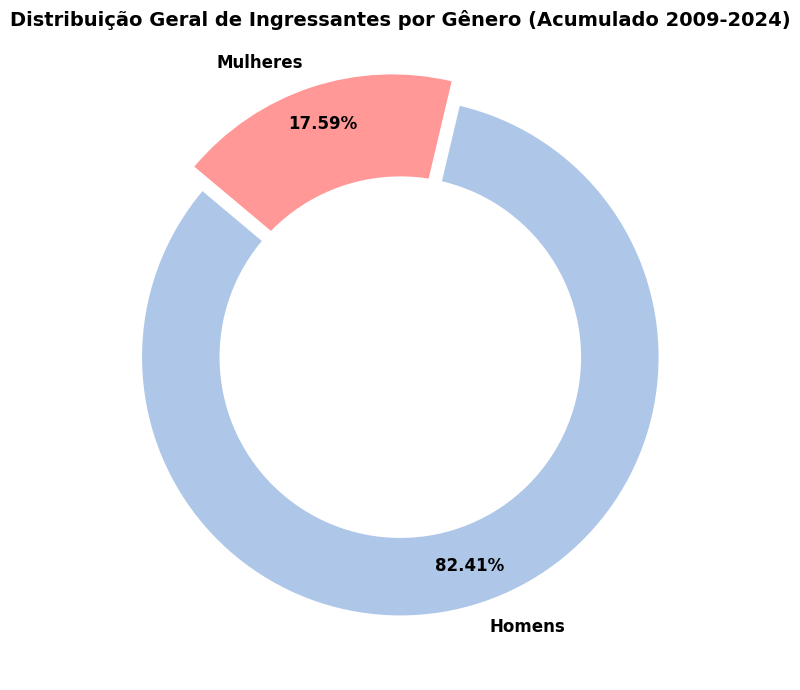

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Recalcular as variáveis necessárias para garantir que existam no estado atual do kernel
total_ingressantes = df['quantidade_ingressantes'].sum()
total_ingressantes_feminino = df['quantidade_ingressantes_feminino'].sum()
porcentagem_feminino = (total_ingressantes_feminino / total_ingressantes) * 100

# --- 1. GRÁFICO DO PERCENTUAL CONSOLIDADO DE MULHERES INGRESSANTES (2009-2024) ---
labels = ['Homens', 'Mulheres']
sizes = [100 - porcentagem_feminino, porcentagem_feminino]
colors = ['#aec7e8', '#ff9896']
explode = (0, 0.1)  # destaca a fatia de mulheres

plt.figure(figsize=(7, 7))
plt.pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.2f%%', startangle=140, pctdistance=0.85, shadow=False, textprops={'fontsize': 12, 'weight': 'bold'})

# Desenhar um círculo no centro para transformar em gráfico de rosca (donut chart)
centre_circle = plt.Circle((0,0),0.70,fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

plt.title('Distribuição Geral de Ingressantes por Gênero (Acumulado 2009-2024)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# Agrupando por ano e somando os ingressantes gerais e femininos
ingressantes_por_ano = df.groupby('ano')[['quantidade_ingressantes', 'quantidade_ingressantes_feminino']].sum().reset_index()

# Calculando o percentual de mulheres para cada ano
ingressantes_por_ano['percentual_mulheres'] = (ingressantes_por_ano['quantidade_ingressantes_feminino'] / ingressantes_por_ano['quantidade_ingressantes']) * 100

# Exibindo o resultado formatado
print("--- Percentual de Mulheres Ingressantes por Ano ---")
for index, row in ingressantes_por_ano.iterrows():
    print(f"Ano {row['ano']}: {row['percentual_mulheres']:.2f}% ({row['quantidade_ingressantes_feminino']:,.0f} de {row['quantidade_ingressantes']:,.0f} ingressantes)")

--- Percentual de Mulheres Ingressantes por Ano ---
Ano 2009: 17.08% (19,468 de 113,950 ingressantes)
Ano 2010: 15.85% (18,720 de 118,081 ingressantes)
Ano 2011: 15.52% (19,495 de 125,575 ingressantes)
Ano 2012: 15.25% (21,708 de 142,380 ingressantes)
Ano 2013: 15.11% (20,877 de 138,170 ingressantes)
Ano 2014: 14.48% (21,147 de 146,024 ingressantes)
Ano 2015: 13.60% (19,212 de 141,260 ingressantes)
Ano 2016: 13.55% (19,023 de 140,425 ingressantes)
Ano 2017: 13.43% (20,245 de 150,745 ingressantes)
Ano 2018: 13.71% (22,439 de 163,683 ingressantes)
Ano 2019: 14.64% (26,926 de 183,895 ingressantes)
Ano 2020: 16.58% (37,683 de 227,281 ingressantes)
Ano 2021: 18.95% (51,607 de 272,329 ingressantes)
Ano 2022: 20.45% (83,924 de 410,454 ingressantes)
Ano 2023: 20.64% (97,615 de 472,830 ingressantes)
Ano 2024: 21.30% (104,176 de 489,067 ingressantes)


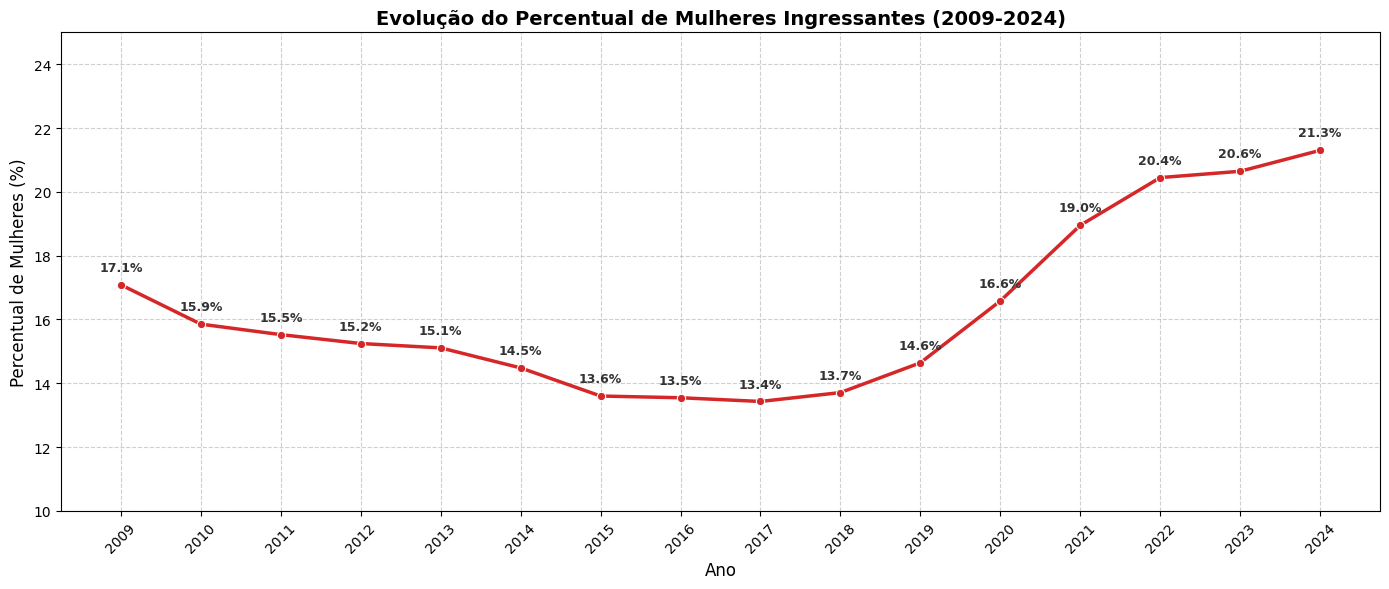

In [ ]:
# Recalcular o agrupamento anual para garantir que exista no estado atual do kernel
ingressantes_por_ano = df.groupby('ano')[['quantidade_ingressantes', 'quantidade_ingressantes_feminino']].sum().reset_index()
ingressantes_por_ano['percentual_mulheres'] = (ingressantes_por_ano['quantidade_ingressantes_feminino'] / ingressantes_por_ano['quantidade_ingressantes']) * 100

# --- 2. GRÁFICO DE LINHA DA EVOLUÇÃO TEMPORAL (ANO A ANO) ---
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 6))
sns.lineplot(
    data=ingressantes_por_ano,
    x='ano',
    y='percentual_mulheres',
    marker='o',
    linewidth=2.5,
    color='#d62728'
)

# Adicionar o percentual exato em cada ano
for index, row in ingressantes_por_ano.iterrows():
    plt.annotate(f"{row['percentual_mulheres']:.1f}%",
                 (row['ano'], row['percentual_mulheres']),
                 textcoords="offset points",
                 xytext=(0,10),
                 ha='center',
                 fontsize=9,
                 fontweight='bold',
                 color='#333333')

plt.title('Evolução do Percentual de Mulheres Ingressantes (2009-2024)', fontsize=14, fontweight='bold')
plt.xlabel('Ano', fontsize=12)
plt.ylabel('Percentual de Mulheres (%)', fontsize=12)
plt.ylim(10, 25)
plt.xticks(ingressantes_por_ano['ano'], rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

Conclusões:
- O percentual de mulheres ingressantes começou em 17,08% em 2009 e entrou em uma trajetória de queda quase constante, atingindo a sua mínima histórica em 2017 com apenas 13,43%.
- A partir de 2018, o cenário começou a mudar de forma consistente. O percentual subiu ano a ano: 13,71% (2018) -> 16,58% (2020) -> 18,95% (2021) -> até ultrapassar a barreira dos 20%.
- Em 2024, atingimos a máxima histórica da série temporal com 21,30% de mulheres ingressantes.

Se em 2009 tínhamos pouco mais de 19 mil mulheres entrando na área, em 2024 esse número saltou para 104.176 mulheres.
Embora o número total de vagas tenha aumentado imensamente para todos (de 113 mil para quase 490 mil no total), a proporção de mulheres cresceu em um ritmo ainda mais acelerado nos últimos anos.

Resumo: O cenário já foi mais crítico em 2017, mas hoje as mulheres vêm conquistando cada vez mais espaço e já representam mais de 21% de quem inicia a trajetória nos cursos de Computação e TIC no Brasil.

---

2. MATRÍCULAS

In [ ]:
# 1. Quantidade total e percentual acumulado de matrículas masculinas vs. femininas (2009-2024)
total_matriculas = df['quantidade_matriculas'].sum()
total_matriculas_feminino = df['quantidade_matriculas_feminino'].sum()

if total_matriculas > 0:
    porcentagem_matriculas_feminino = (total_matriculas_feminino / total_matriculas) * 100
    print(f"Total Geral de Matrículas (Acumulado): {total_matriculas:,.0f}")
    print(f"Total de Mulheres Matriculadas (Acumulado): {total_matriculas_feminino:,.0f}")
    print(f"Percentual de Mulheres Matriculadas: {porcentagem_matriculas_feminino:.2f}%")
else:
    print("Nenhum registro de matrícula encontrado.")

Total Geral de Matrículas (Acumulado): 6,457,099
Total de Mulheres Matriculadas (Acumulado): 1,041,008
Percentual de Mulheres Matriculadas: 16.12%


2.1. Cenário Geral Acumulado (2009-2024)

- Volume Total: Foram registradas mais de 6,4 milhões de matrículas ativas na área de Computação e TIC no Brasil ao longo deste período de 16 anos.
- Representação Feminina: Desse volume imenso, as mulheres representam 16,12% (pouco mais de 1 milhão de matrículas acumuladas).
- Insight Comparativo: Observe que a taxa de matrícula feminina acumulada (16,12%) é ligeiramente inferior à de ingresso (17,59%). Isso sugere uma tendência histórica de maior evasão (desistência) de mulheres ou uma entrada mais tardia (recente) que ainda não acumulou o mesmo volume de matrículas de longo prazo.

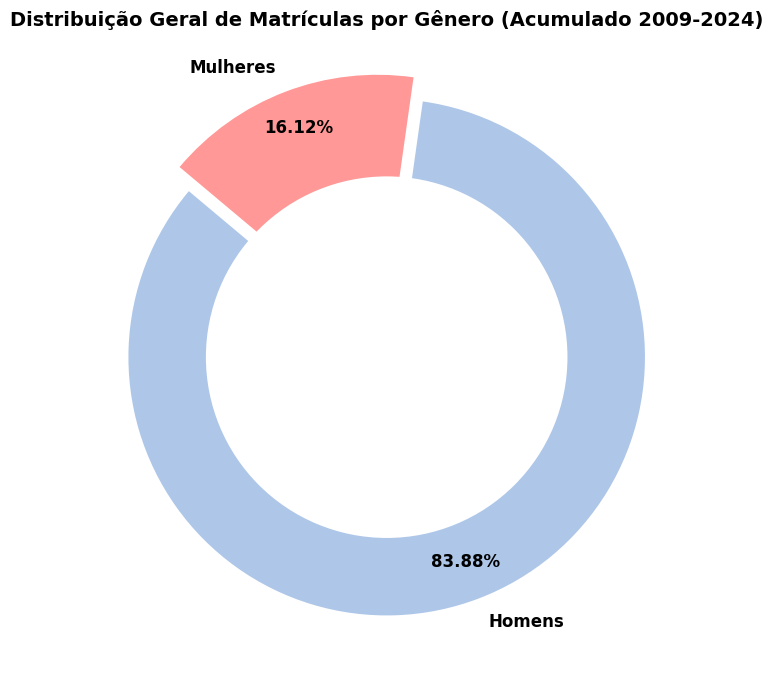

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# --- GRÁFICO DO PERCENTUAL CONSOLIDADO DE MATRÍCULAS POR GÊNERO ---
labels = ['Homens', 'Mulheres']
sizes = [100 - porcentagem_matriculas_feminino, porcentagem_matriculas_feminino]
colors = ['#aec7e8', '#ff9896']
explode = (0, 0.1)

plt.figure(figsize=(7, 7))
plt.pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.2f%%', startangle=140, pctdistance=0.85, shadow=False, textprops={'fontsize': 12, 'weight': 'bold'})

centre_circle = plt.Circle((0,0),0.70,fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

plt.title('Distribuição Geral de Matrículas por Gênero (Acumulado 2009-2024)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
#  Evolução temporal ano a ano das matrículas por gênero
matriculas_por_ano = df.groupby('ano')[['quantidade_matriculas', 'quantidade_matriculas_feminino']].sum().reset_index()
matriculas_por_ano['percentual_mulheres'] = (matriculas_por_ano['quantidade_matriculas_feminino'] / matriculas_por_ano['quantidade_matriculas']) * 100

print("--- Percentual de Mulheres Matriculadas por Ano ---")
for index, row in matriculas_por_ano.iterrows():
    print(f"Ano {row['ano']}: {row['percentual_mulheres']:.2f}% ({row['quantidade_matriculas_feminino']:,.0f} de {row['quantidade_matriculas']:,.0f} matrículas)")

--- Percentual de Mulheres Matriculadas por Ano ---
Ano 2009: 17.23% (47,627 de 276,489 matrículas)
Ano 2010: 16.29% (48,096 de 295,257 matrículas)
Ano 2011: 15.92% (49,336 de 309,849 matrículas)
Ano 2012: 15.48% (48,158 de 311,013 matrículas)
Ano 2013: 15.02% (47,914 de 318,948 matrículas)
Ano 2014: 14.61% (47,319 de 323,780 matrículas)
Ano 2015: 14.05% (45,076 de 320,844 matrículas)
Ano 2016: 13.65% (42,474 de 311,147 matrículas)
Ano 2017: 13.35% (42,520 de 318,384 matrículas)
Ano 2018: 13.16% (43,943 de 333,997 matrículas)
Ano 2019: 13.54% (47,944 de 354,160 matrículas)
Ano 2020: 14.77% (59,022 de 399,675 matrículas)
Ano 2021: 16.31% (75,701 de 464,269 matrículas)
Ano 2022: 17.94% (106,692 de 594,580 matrículas)
Ano 2023: 18.67% (135,255 de 724,485 matrículas)
Ano 2024: 19.24% (153,931 de 800,222 matrículas)


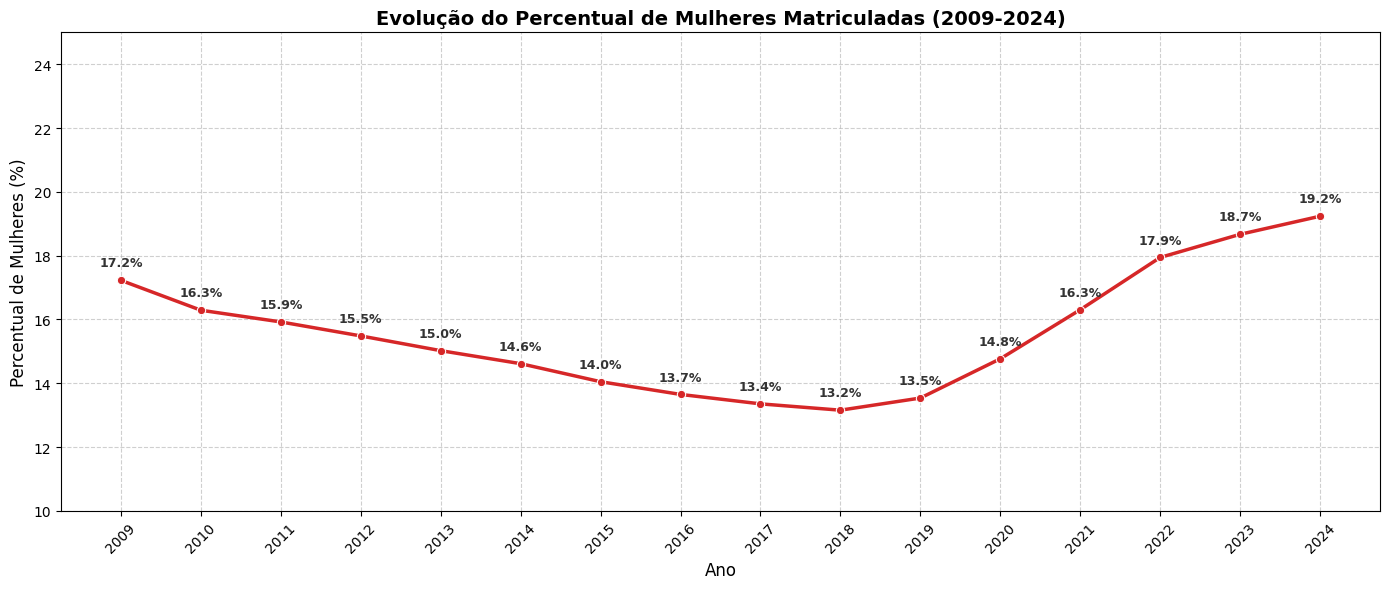

In [ ]:
# --- GRÁFICO DE EVOLUÇÃO DAS MATRÍCULAS DE MULHERES ---
plt.figure(figsize=(14, 6))
sns.lineplot(
    data=matriculas_por_ano,
    x='ano',
    y='percentual_mulheres',
    marker='o',
    linewidth=2.5,
    color='#d62728'
)

for index, row in matriculas_por_ano.iterrows():
    plt.annotate(f"{row['percentual_mulheres']:.1f}%",
                 (row['ano'], row['percentual_mulheres']),
                 textcoords="offset points",
                 xytext=(0,10),
                 ha='center',
                 fontsize=9,
                 fontweight='bold',
                 color='#333333')

plt.title('Evolução do Percentual de Mulheres Matriculadas (2009-2024)', fontsize=14, fontweight='bold')
plt.xlabel('Ano', fontsize=12)
plt.ylabel('Percentual de Mulheres (%)', fontsize=12)
plt.ylim(10, 25)
plt.xticks(matriculas_por_ano['ano'], rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

2.2 Evolução Histórica Ano a Ano (Tendência Temporal)

Analisando a trajetória anual das matrículas de mulheres, vemos um comportamento em formato de "U", muito semelhante ao dos ingressantes, mas com uma leve defasagem temporal:

A Queda Histórica (2009 a 2018):

- Em 2009, o percentual de mulheres matriculadas era de 17,23%.
Houve uma queda ininterrupta ano a ano por quase uma década, atingindo o mínimo histórico em 2018 com apenas 13,16%.
A Retomada e o Crescimento Exponencial (2019 a 2024):

- A partir de 2019, o cenário vira de forma muito expressiva: 13,54% (2019) → 14,77% (2020) → 16,31% (2021) → 17,94% (2022) → 18,67% (2023) → 19,24% (2024).
- Em termos absolutos, o número de mulheres matriculadas ativas na área triplicou, saltando de 47.627 em 2009 para 153.931 mulheres matriculadas em 2024.

Resumo

Apesar de o acumulado geral ser de 16,12%, o momento atual (2024) registra o melhor patamar de presença feminina em matrículas ativas de toda a série histórica, beirando os 19,24%. Isso demonstra o impacto direto do aumento recente de ingressantes mulheres refletindo agora nas turmas ativas.

3. CONCLUINTES

In [ ]:
# 1. Quantidade total e percentual acumulado de concluintes masculinos vs. femininos (2009-2024)
total_concluintes = df['quantidade_concluintes'].sum()
total_concluintes_feminino = df['quantidade_concluintes_feminino'].sum()

if total_concluintes > 0:
    porcentagem_concluintes_feminino = (total_concluintes_feminino / total_concluintes) * 100
    print(f"Total Geral de Concluintes (Acumulado): {total_concluintes:,.0f}")
    print(f"Total de Mulheres Concluintes (Acumulado): {total_concluintes_feminino:,.0f}")
    print(f"Percentual de Mulheres Concluintes: {porcentagem_concluintes_feminino:.2f}%")
else:
    print("Nenhum registro de concluinte encontrado.")

Total Geral de Concluintes (Acumulado): 814,758
Total de Mulheres Concluintes (Acumulado): 132,057
Percentual de Mulheres Concluintes: 16.21%


3.1 Cenário Geral Acumulado de Concluintes (2009-2024)



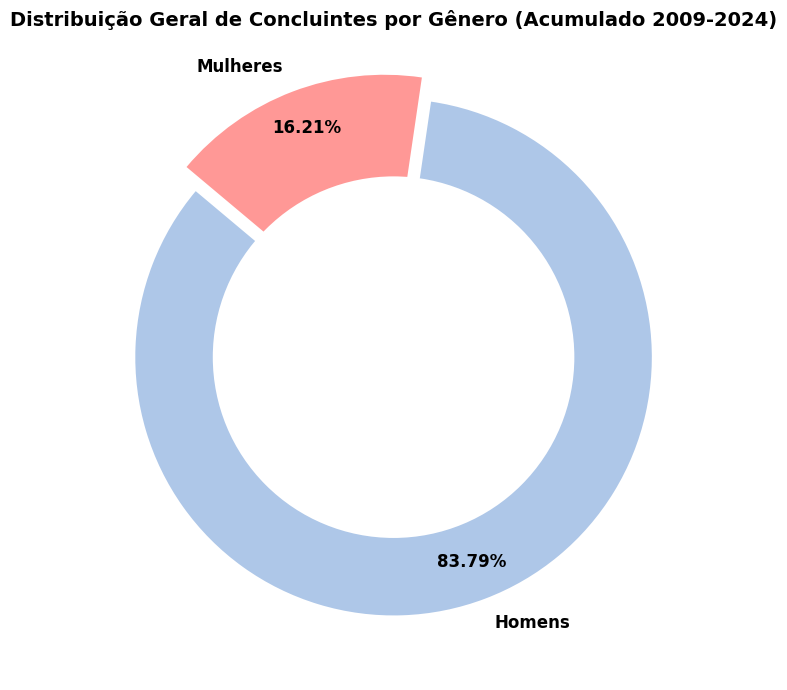

In [ ]:
import matplotlib.pyplot as plt

# --- GRÁFICO DO PERCENTUAL CONSOLIDADO DE CONCLUINTES POR GÊNERO ---
labels = ['Homens', 'Mulheres']
sizes = [100 - porcentagem_concluintes_feminino, porcentagem_concluintes_feminino]
colors = ['#aec7e8', '#ff9896']
explode = (0, 0.1)

plt.figure(figsize=(7, 7))
plt.pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.2f%%', startangle=140, pctdistance=0.85, shadow=False, textprops={'fontsize': 12, 'weight': 'bold'})

centre_circle = plt.Circle((0,0),0.70,fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

plt.title('Distribuição Geral de Concluintes por Gênero (Acumulado 2009-2024)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

Analisando o desfecho da trajetória acadêmica através dos dados de **concluintes**, observamos comportamentos cruciais para entender a retenção e formação de mulheres na área de Computação e TIC:

3.2 Cenário Geral Acumulado (2009-2024)
* **Volume Total de Diplomados:** Ao longo dos 15 anos analisados, o Brasil formou **814.758 novos profissionais** na área.
* **Representação Feminina:** Desse total, **132.057 foram mulheres**, o que equivale a um percentual acumulado de **16,21%**.
* **Equilíbrio Saudável:** É extremamente positivo notar que o percentual de concluintes acumulado (16,21%) é muito próximo ao de matrículas (16,12%) e ao de ingressantes históricos (17,59%). Isso sugere que, embora haja barreiras de entrada, a taxa de sucesso acadêmico (diplomação) das mulheres que permanecem na faculdade é proporcionalmente competitiva e sólida.

3.3 Evolução Histórica Ano a Ano (Tendência Temporal para Concluintes)


In [ ]:
#Evolução temporal ano a ano dos concluintes por gênero
concluintes_por_ano = df.groupby('ano')[['quantidade_concluintes', 'quantidade_concluintes_feminino']].sum().reset_index()
concluintes_por_ano['percentual_mulheres'] = (concluintes_por_ano['quantidade_concluintes_feminino'] / concluintes_por_ano['quantidade_concluintes']) * 100

print("--- Percentual de Mulheres Concluintes por Ano ---")
for index, row in concluintes_por_ano.iterrows():
    print(f"Ano {row['ano']}: {row['percentual_mulheres']:.2f}% ({row['quantidade_concluintes_feminino']:,.0f} de {row['quantidade_concluintes']:,.0f} concluintes)")

--- Percentual de Mulheres Concluintes por Ano ---
Ano 2009: 18.61% (7,706 de 41,417 concluintes)
Ano 2010: 18.08% (7,351 de 40,651 concluintes)
Ano 2011: 17.07% (7,004 de 41,021 concluintes)
Ano 2012: 17.37% (7,234 de 41,644 concluintes)
Ano 2013: 16.34% (6,612 de 40,476 concluintes)
Ano 2014: 15.60% (6,562 de 42,072 concluintes)
Ano 2015: 15.34% (6,786 de 44,247 concluintes)
Ano 2016: 14.70% (6,489 de 44,132 concluintes)
Ano 2017: 14.63% (6,131 de 41,918 concluintes)
Ano 2018: 13.82% (6,021 de 43,562 concluintes)
Ano 2019: 13.59% (6,101 de 44,891 concluintes)
Ano 2020: 13.96% (7,197 de 51,567 concluintes)
Ano 2021: 14.85% (8,106 de 54,596 concluintes)
Ano 2022: 15.34% (9,474 de 61,760 concluintes)
Ano 2023: 17.47% (14,030 de 80,316 concluintes)
Ano 2024: 19.16% (19,253 de 100,488 concluintes)


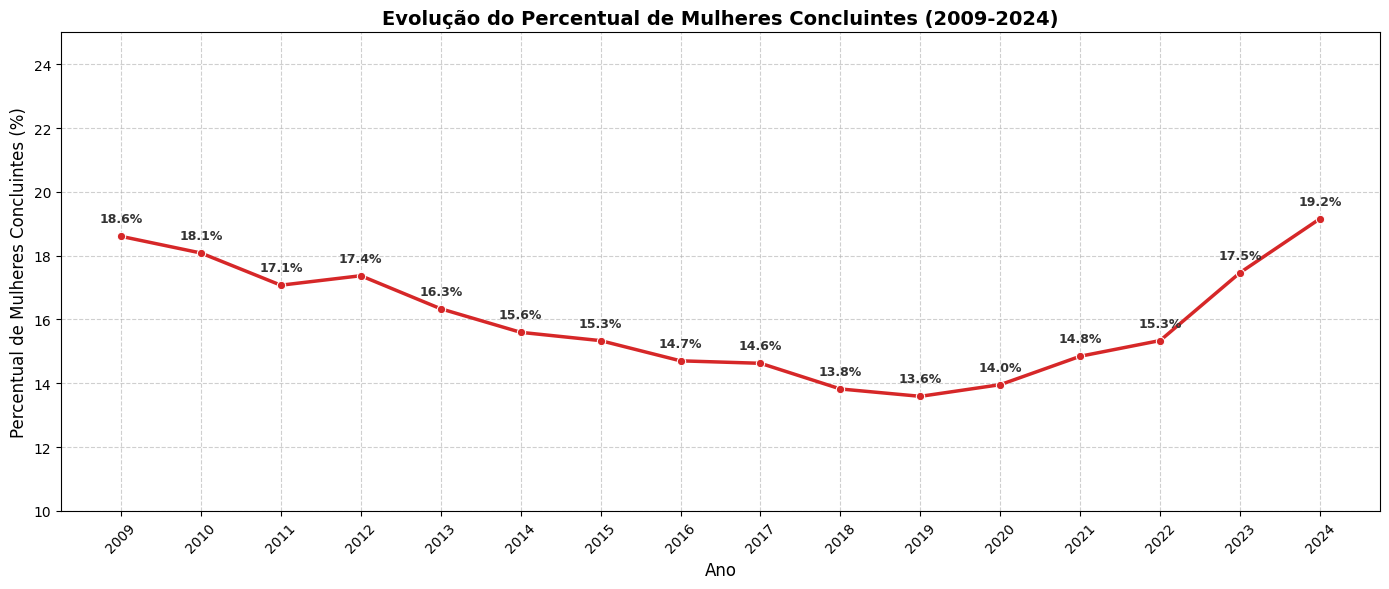

In [ ]:
# --- GRÁFICO DE EVOLUÇÃO DOS CONCLUINTES DE MULHERES ---
plt.figure(figsize=(14, 6))
sns.lineplot(
    data=concluintes_por_ano,
    x='ano',
    y='percentual_mulheres',
    marker='o',
    linewidth=2.5,
    color='#d62728'
)

for index, row in concluintes_por_ano.iterrows():
    plt.annotate(f"{row['percentual_mulheres']:.1f}%",
                 (row['ano'], row['percentual_mulheres']),
                 textcoords="offset points",
                 xytext=(0,10),
                 ha='center',
                 fontsize=9,
                 fontweight='bold',
                 color='#333333')

plt.title('Evolução do Percentual de Mulheres Concluintes (2009-2024)', fontsize=14, fontweight='bold')
plt.xlabel('Ano', fontsize=12)
plt.ylabel('Percentual de Mulheres Concluintes (%)', fontsize=12)
plt.ylim(10, 25)
plt.xticks(concluintes_por_ano['ano'], rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()



3.4 Evolução Histórica Ano a Ano (Tendência Temporal)
Assim como nos indicadores anteriores, o histórico de concluintes desenha uma curva nítida em formato de "U":

* **A Queda Sistêmica (2009-2019):** Em 2009, as mulheres representavam **18,61%** de todos os graduados da área. Essa participação encolheu anualmente até atingir seu ponto mais baixo em 2019, quando apenas **13,59%** dos formados eram do gênero feminino.
* **A Rápida Recuperação (2020-2024):** A partir de 2020, os efeitos do reaquecimento nos ingressos começaram a chegar à formatura. O percentual subiu progressivamente: `13,96% (2020) → 14,85% (2021) → 15,34% (2022) → 17,47% (2023) → 19,16% (2024)`.
* **O Recorde Histórico:** Em 2024, o mercado de tecnologia recebeu o maior contingente feminino da história, registrando **19.253 mulheres formadas** em um único ano, estabelecendo o ápice histórico de **19,16%** de representação entre os concluintes.

---

###4. Conclusão e Resumo da Jornada Feminina na Computação (2009-2024)

Com todas as análises de Ingressantes, Matrículas e Concluintes, temos um panorama definitivo de ponta a ponta sobre a presença das mulheres nos cursos de Tecnologia da Informação (TIC) no Brasil:

1. Ingresso (A Entrada):

 - Acumulado: 17,59% das pessoas que entram são mulheres.
 - Momento Atual (2024): Atingimos o pico histórico com 21,30% de ingressantes mulheres (mais de 104 mil novas alunas).

2. Permanência (O Meio do Caminho):

 - Acumulado: Mulheres representam 16,12% de todas as matrículas ativas na história.
 - Momento Atual (2024): Representam 19,24% do corpo discente ativo (mais de 153 mil alunas simultâneas).

3. Graduação (A Saída para o Mercado):

 - Acumulado: Mulheres representam 16,21% de todas as formadas.
 - Momento Atual (2024): Atingimos o recorde histórico com 19,16% de concluintes mulheres, resultando em 19.253 novas profissionais qualificadas no mercado em apenas um ano.
####Análise da Curva em "U"
Os três indicadores apontam com exatidão que o pior momento para a diversidade de gênero na computação brasileira ocorreu entre 2017 e 2019 (com taxas de representação caindo para a faixa dos 13%). A partir de então, políticas de incentivo e atratividade começaram a dar resultados expressivos, levando as taxas aos patamares históricos máximos de 2024.

####Diagnóstico Completo da Presença Feminina (2009-2024)
Com a conclusão das três grandes etapas do ciclo universitário (Ingresso, Matrícula e Conclusão), temos um panorama definitivo sobre a participação das mulheres nos cursos de Computação e TIC no Brasil:

1. A Entrada (Ingressantes):

 - Média Histórica: 17,59%
 - Situação Atual (2024): Recorde histórico de 21,30% de ingressantes mulheres.

2. A Permanência (Matrículas Ativas):

 - Média Histórica: 16,12%
 - Situação Atual (2024): Recorde histórico de 19,24% das matrículas totais.

3. A Saída (Concluintes/Graduados):

 - Média Histórica: 16,21%
 - Situação Atual (2024): Recorde histórico de 19,16% de graduadas (representando 19.253 mulheres diplomadas em Computação no ano).

####Conclusão Principal
Os três indicadores mostram o mesmo comportamento em formato de "U": uma queda sistemática que começou em 2009, atingiu o pior nível histórico no triênio 2017-2019 (onde as mulheres representavam apenas ~13% do total) e iniciou uma retomada acelerada a partir de 2020.

O fato de o percentual de concluintes de 2024 (19,16%) ser muito próximo do percentual de matrículas (19,24%) indica que a retenção e o sucesso acadêmico das mulheres que entram na área é forte e proporcional ao dos homens.


####Diagnóstico Completo da Presença Feminina (2009-2024)
Com a conclusão das três grandes etapas do ciclo universitário (Ingresso, Matrícula e Conclusão), temos um panorama definitivo sobre a participação das mulheres nos cursos de Computação e TIC no Brasil:

1. A Entrada (Ingressantes):

 - Média Histórica: 17,59%
 - Situação Atual (2024): Recorde histórico de 21,30% de ingressantes mulheres.

2. A Permanência (Matrículas Ativas):

 - Média Histórica: 16,12%
 - Situação Atual (2024): Recorde histórico de 19,24% das matrículas totais.

3. A Saída (Concluintes/Graduados):

 - Média Histórica: 16,21%
 - Situação Atual (2024): Recorde histórico de 19,16% de graduadas (representando 19.253 mulheres diplomadas em Computação no ano).

####Conclusão Principal
Os três indicadores mostram o mesmo comportamento em formato de "U": uma queda sistemática que começou em 2009, atingiu o pior nível histórico no triênio 2017-2019 (onde as mulheres representavam apenas ~13% do total) e iniciou uma retomada acelerada a partir de 2020.

O fato de o percentual de concluintes de 2024 (19,16%) ser muito próximo do percentual de matrículas (19,24%) indica que a retenção e o sucesso acadêmico das mulheres que entram na área é forte e proporcional ao dos homens.

---

5. ANÁLISE POR ESTADO

Avaliação do volume acumulado de ingressantes e matrículas, bem como o percentual de representatividade de mulheres para cada uma das unidades federativas de forma independente.

In [ ]:
import pandas as pd

# 1. Agrupar os dados por estado para calcular os totais
ranking_estados = df.groupby('sigla_uf')[[
    'quantidade_ingressantes',
    'quantidade_ingressantes_feminino',
    'quantidade_matriculas',
    'quantidade_matriculas_feminino'
]].sum().reset_index()

# 2. Calcular os percentuais de participação feminina por estado
ranking_estados['pct_mulheres_ingressantes'] = (ranking_estados['quantidade_ingressantes_feminino'] / ranking_estados['quantidade_ingressantes']) * 100
ranking_estados['pct_mulheres_matriculadas'] = (ranking_estados['quantidade_matriculas_feminino'] / ranking_estados['quantidade_matriculas']) * 100

# 3. Ordenar o ranking pelo volume de matrículas para manter a coerência com o enunciado
ranking_estados = ranking_estados.sort_values(by='quantidade_matriculas', ascending=False).reset_index(drop=True)
ranking_estados.index = ranking_estados.index + 1
ranking_estados.index.name = 'Colocação'

# Exibindo o ranking detalhado dos 15 estados com mais matrículas acumuladas para conferência dos valores
display(ranking_estados[['sigla_uf', 'quantidade_ingressantes', 'quantidade_ingressantes_feminino', 'pct_mulheres_ingressantes', 'quantidade_matriculas', 'quantidade_matriculas_feminino', 'pct_mulheres_matriculadas']].head(15))

,sigla_uf,quantidade_ingressantes,quantidade_ingressantes_feminino,pct_mulheres_ingressantes,quantidade_matriculas,quantidade_matriculas_feminino,pct_mulheres_matriculadas
Colocação,,,,,,,
1,SP,1217396,230907,18.967288,2133807,373597,17.508472
2,MG,274896,48019,17.468061,564962,91327,16.165158
3,RJ,278619,47348,16.993816,559757,88094,15.737901
4,RS,202403,33207,16.406377,409214,57716,14.104112
5,PR,218165,37056,16.985309,386019,56374,14.603944
6,SC,143428,24596,17.148674,274511,41044,14.951678
7,DF,144285,25654,17.780088,265451,43907,16.540529
8,CE,110828,18236,16.454326,227490,34052,14.96857
9,PE,113897,19869,17.444709,220691,34137,15.468234


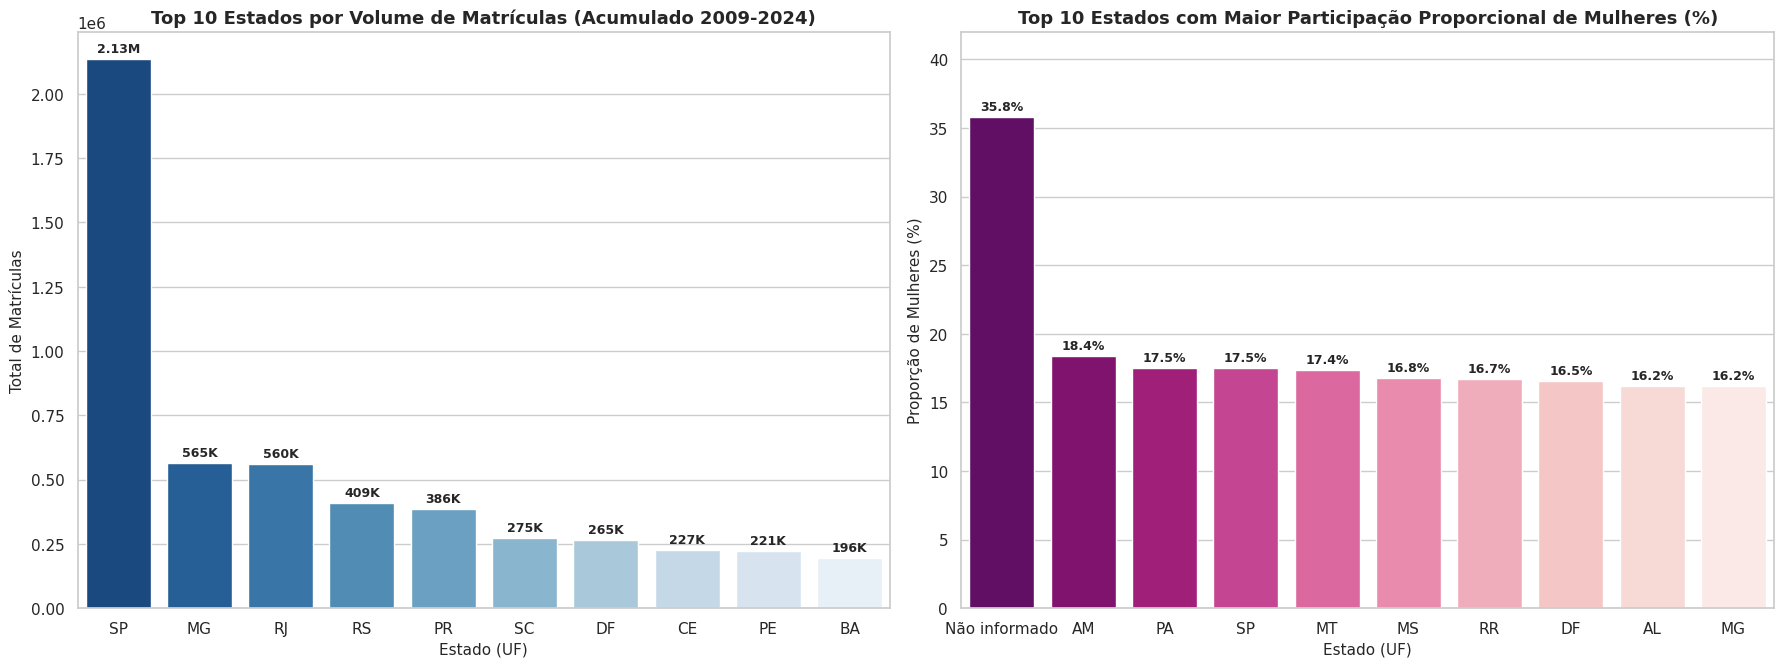

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar o estilo visual
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# 1. Gráfico de Barras: Top 10 Estados por Volume de Matrículas
df_grafico_volume_top10 = ranking_estados.head(10).copy()

sns.barplot(
    data=df_grafico_volume_top10,
    x='sigla_uf',
    y='quantidade_matriculas',
    ax=axes[0],
    palette='Blues_r',
    hue='sigla_uf',
    legend=False
)
axes[0].set_title('Top 10 Estados por Volume de Matrículas (Acumulado 2009-2024)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Estado (UF)', fontsize=11)
axes[0].set_ylabel('Total de Matrículas', fontsize=11)

# Adicionar os valores formatados acima das barras do Top 10
for p in axes[0].patches:
    val = p.get_height()
    if val > 0:
        axes[0].annotate(f"{val/1e6:.2f}M" if val >= 1e6 else f"{val/1e3:.0f}K",
                     (p.get_x() + p.get_width() / 2., val),
                     textcoords="offset points",
                     xytext=(0,5),
                     ha='center',
                     fontsize=9,
                     fontweight='bold')

# 2. Gráfico de Barras: Top 10 Estados por Proporção de Mulheres
df_grafico_proporcao_top10 = ranking_estados.sort_values(by='pct_mulheres_matriculadas', ascending=False).head(10).copy()

sns.barplot(
    data=df_grafico_proporcao_top10,
    x='sigla_uf',
    y='pct_mulheres_matriculadas',
    ax=axes[1],
    palette='RdPu_r',
    hue='sigla_uf',
    legend=False
)
axes[1].set_title('Top 10 Estados com Maior Participação Proporcional de Mulheres (%)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Estado (UF)', fontsize=11)
axes[1].set_ylabel('Proporção de Mulheres (%)', fontsize=11)
axes[1].set_ylim(0, 42)  # Limite vertical fixo para manter consistência e dar espaço para rótulos

# Adicionar o percentual exato acima de cada barra do Top 10 proporcional
for p in axes[1].patches:
    val = p.get_height()
    if val > 0:
        axes[1].annotate(f"{val:.1f}%",
                     (p.get_x() + p.get_width() / 2., val),
                     textcoords="offset points",
                     xytext=(0,5),
                     ha='center',
                     fontsize=9,
                     fontweight='bold')

plt.tight_layout()
plt.show()

### 📊 Análise Detalhada da Participação Feminina por Estado

A partir dos dados consolidados de **Ingressantes**, **Matrículas** e **Concluintes** por Unidade Federativa (UF), podemos extrair diagnósticos fundamentais sobre a distribuição geográfica e a representatividade feminina na área de Computação e TIC:

#### 1. Concentração Massiva no Estado de São Paulo (SP)
* **Domínio Absoluto:** O estado de São Paulo é o maior polo de educação em tecnologia do país por uma margem gigantesca. Com **mais de 2,1 milhões de matrículas acumuladas**, ele supera com folga a soma dos próximos estados do ranking.
* **Comparação de Volume:** Enquanto SP registra mais de 2,13M de matrículas, os segundos e terceiros colocados, Minas Gerais (MG) e Rio de Janeiro (RJ), possuem cerca de **565 mil** e **560 mil** matrículas, respectivamente.

#### 2. O Caso dos Dados "Não Informados"
* Nos gráficos e tabelas, a categoria **"Não informado"** apresenta um percentual surpreendentemente alto de participação feminina (cerca de **35,8%** nas matrículas e **34,8%** nos concluintes).
* Isso ocorre porque registros que carecem de identificação geográfica precisa (geralmente de cursos antigos ou de plataformas específicas de EAD com preenchimento incompleto no Censo) historicamente continham uma proporção diferente de distribuição ou erros de declaração, mas representam um volume muito pequeno em termos absolutos.

#### 3. Líderes em Representatividade Feminina Real
Excluindo os registros sem estado declarado, os estados que de fato se destacam com a maior proporção de mulheres nas salas de aula e na colação de grau são:

* **Amazonas (AM):** Lidera o ranking de representatividade real com **18,4%** de mulheres matriculadas e **18,8%** de concluintes mulheres.
* **Pará (PA) e Alagoas (AL):** Apresentam excelente desempenho relativo, figurando no topo das taxas proporcionais (~17,5% a 18,3%).
* **São Paulo (SP):** Além de ser o maior em volume absoluto, consegue manter uma taxa de representação muito saudável de **17,4%** de mulheres nas matrículas ativas e **17,6%** de concluintes mulheres, mostrando que a força de SP dita a média nacional.

#### 4. Estados de Grande Volume vs. Desafio de Inclusão
* **Minas Gerais (MG):** Apesar de ser o segundo maior estado em volume absoluto de matrículas (565K) e formandos (69,3K), a proporção de mulheres é de apenas **16,2%** nas matrículas e **16,3%** nos concluintes, ficando ligeiramente abaixo da média de grandes polos como SP.
* **Rio de Janeiro (RJ):** Segue um comportamento muito similar a MG, com **16,3%** de representação feminina entre as concluintes.

=== RANKING GERAL DE CONCLUINTES POR ESTADO (ACUMULADO 2009-2024) ===


,sigla_uf,quantidade_concluintes,quantidade_concluintes_feminino,pct_mulheres_concluintes
Colocação,,,,
1,SP,320908,56461,17.594139
2,MG,69252,11306,16.325882
3,RJ,63317,10328,16.311575
4,PR,48908,6793,13.889343
5,RS,43242,5951,13.762083
6,DF,38874,6611,17.006225
7,SC,31628,4621,14.610472
8,PE,24050,3607,14.997921
9,BA,22753,3091,13.585022


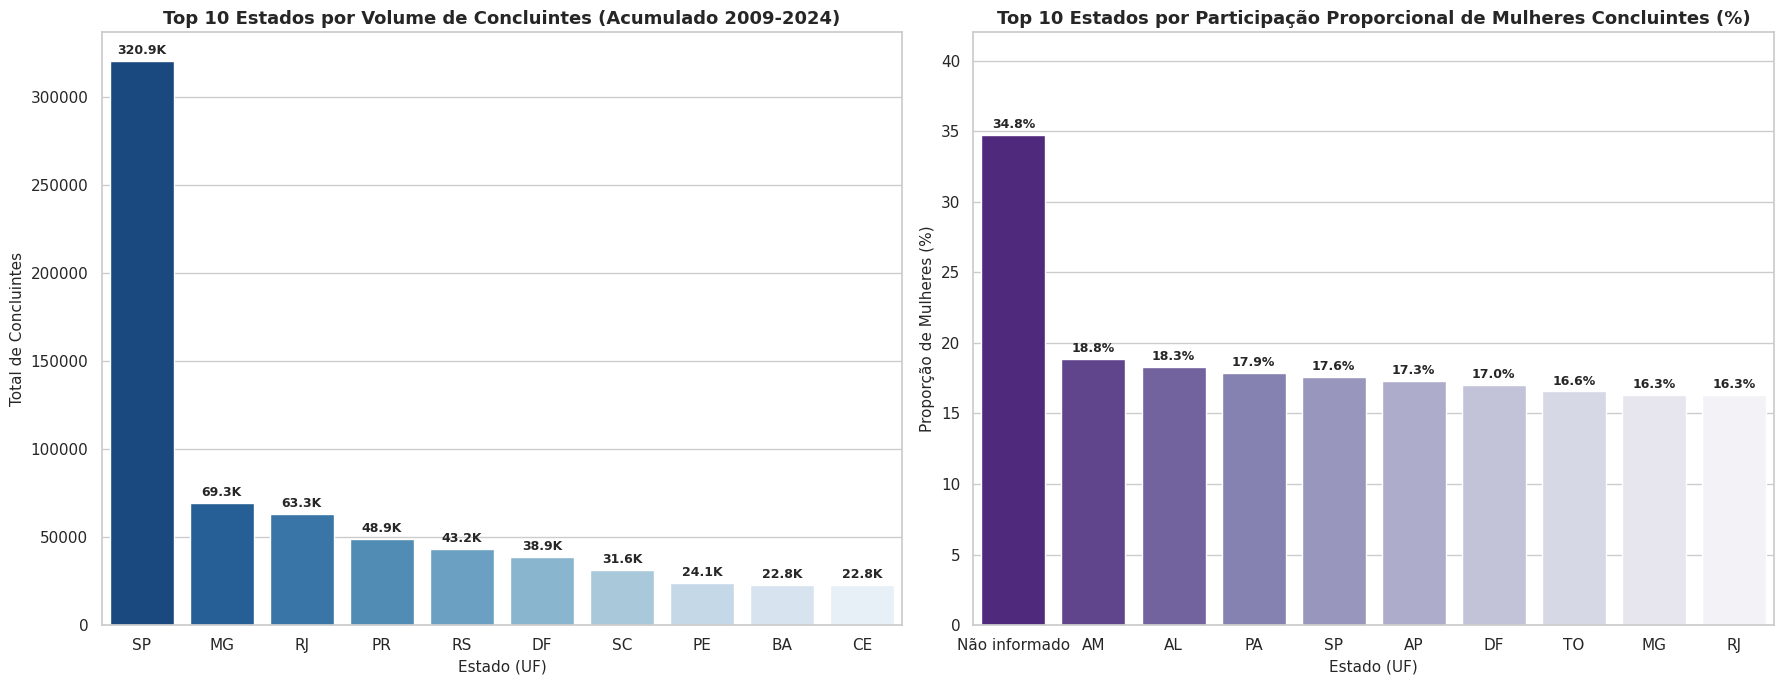

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Agrupar dados por UF para calcular os concluintes totais e femininos
analise_concluintes_estado = df.groupby('sigla_uf')[['quantidade_concluintes', 'quantidade_concluintes_feminino']].sum().reset_index()

# 2. Calcular o percentual de mulheres concluintes
analise_concluintes_estado['pct_mulheres_concluintes'] = (
    analise_concluintes_estado['quantidade_concluintes_feminino'] /
    analise_concluintes_estado['quantidade_concluintes']
) * 100

# Ordenar pelo volume total de concluintes para criar o ranking
ranking_concluintes_estados = analise_concluintes_estado.sort_values(by='quantidade_concluintes', ascending=False).reset_index(drop=True)
ranking_concluintes_estados.index = ranking_concluintes_estados.index + 1
ranking_concluintes_estados.index.name = 'Colocação'

print("=== RANKING GERAL DE CONCLUINTES POR ESTADO (ACUMULADO 2009-2024) ===")
display(ranking_concluintes_estados[['sigla_uf', 'quantidade_concluintes', 'quantidade_concluintes_feminino', 'pct_mulheres_concluintes']].head(15))

# 3. Configurar os gráficos comparativos
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Gráfico 1: Top 10 Estados por Volume de Concluintes
df_concluintes_volume_top10 = ranking_concluintes_estados.head(10).copy()

sns.barplot(
    data=df_concluintes_volume_top10,
    x='sigla_uf',
    y='quantidade_concluintes',
    ax=axes[0],
    palette='Blues_r',
    hue='sigla_uf',
    legend=False
)
axes[0].set_title('Top 10 Estados por Volume de Concluintes (Acumulado 2009-2024)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Estado (UF)', fontsize=11)
axes[0].set_ylabel('Total de Concluintes', fontsize=11)

# Adicionar rótulos acima das barras de volume
for p in axes[0].patches:
    val = p.get_height()
    if val > 0:
        axes[0].annotate(f"{val/1e3:.1f}K" if val >= 1e3 else f"{val:.0f}",
                     (p.get_x() + p.get_width() / 2., val),
                     textcoords="offset points",
                     xytext=(0,5),
                     ha='center',
                     fontsize=9,
                     fontweight='bold')

# Gráfico 2: Top 10 Estados com Maior Participação Proporcional de Mulheres entre os Concluintes
df_concluintes_proporcao_top10 = ranking_concluintes_estados.sort_values(by='pct_mulheres_concluintes', ascending=False).head(10).copy()

sns.barplot(
    data=df_concluintes_proporcao_top10,
    x='sigla_uf',
    y='pct_mulheres_concluintes',
    ax=axes[1],
    palette='Purples_r',
    hue='sigla_uf',
    legend=False
)
axes[1].set_title('Top 10 Estados por Participação Proporcional de Mulheres Concluintes (%)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Estado (UF)', fontsize=11)
axes[1].set_ylabel('Proporção de Mulheres (%)', fontsize=11)
axes[1].set_ylim(0, 42)

# Adicionar rótulos acima das barras de proporção
for p in axes[1].patches:
    val = p.get_height()
    if val > 0:
        axes[1].annotate(f"{val:.1f}%",
                     (p.get_x() + p.get_width() / 2., val),
                     textcoords="offset points",
                     xytext=(0,5),
                     ha='center',
                     fontsize=9,
                     fontweight='bold')

plt.tight_layout()
plt.show()

1. Dominância Absoluta de São Paulo (SP)

 - Polo Gigante: O estado de São Paulo lidera o ranking nacional com folga extraordinária, registrando 320.908 concluintes acumulados na área de Computação e TIC de 2009 a 2024. Isso é quase 5 vezes mais que o segundo colocado.
 - Sucesso na Formação: Dentre esses concluintes, 56.461 são mulheres, o que representa uma taxa de conclusão feminina bastante sólida de 17,59%, ligeiramente acima da média histórica nacional de concluintes (~16,2%).

2. Minas Gerais (MG) e Rio de Janeiro (RJ) em Equilíbrio
 - MG (2º lugar): Registrou 69.252 concluintes totais, sendo 11.306 mulheres (uma taxa de 16,32%).
 - RJ (3º lugar): Registrou 63.317 concluintes totais, sendo 10.328 mulheres (uma taxa de 16,31%).
 - Ambos os estados mantêm taxas proporcionais idênticas, mas com volume total consideravelmente menor que São Paulo.

3. Destaques de Representatividade Feminina Real (Proporcional)

Se filtrarmos pelos estados com representação real no gráfico (excluindo os registros sem estado preenchido), os locais onde a proporção de mulheres entre os diplomados é mais alta são:

 - Amazonas (AM): Lidera em proporção real com 18,79% de mulheres formadas (1.650 mulheres de um total de 8.759 formados).
 - Alagoas (AL): Apresenta grande destaque proporcional com 18,28% de concluintes mulheres (991 graduadas de um total de 5.422).
 - Pará (PA): Registra 17,89% de mulheres entre os graduados (2.725 graduadas de 15.233 totais).
 - São Paulo (SP): Mantém seus ótimos 17,59%.

4. Desafios Regionais de Inclusão no Sul e Nordeste

- Região Sul: Estados de grande volume como Paraná (PR) com 13,89% e Rio Grande do Sul (RS) com 13,76% figuram entre os menores percentuais de mulheres formadas na história do censo de computação nacional.
- Bahia (BA): Mesmo sendo o 9º estado em volume (22.753 formados), apresenta apenas 13,58% de formandas, mostrando que a atração e retenção de mulheres ainda enfrenta barreiras estruturais significativas nestes locais.

---

6. ANÁLISE POR CURSO

Avaliação do volume acumulado de ingressantes e matrículas, bem como o percentual de representatividade de mulheres para cada curso de Computação e TIC cadastrado, de forma independente.


In [ ]:
import pandas as pd

# 1. Agrupar os dados por curso para calcular os totais
analise_cursos = df.groupby('nome_curso')[[
    'quantidade_matriculas',
    'quantidade_matriculas_feminino'
]].sum().reset_index()

# 2. Calcular o percentual de mulheres matriculadas
analise_cursos['pct_mulheres_matriculadas'] = (analise_cursos['quantidade_matriculas_feminino'] / analise_cursos['quantidade_matriculas']) * 100

# 3. Gerar os Top 15 cursos em volume absoluto de matrículas
top_15_cursos = analise_cursos.sort_values(by='quantidade_matriculas', ascending=False).head(15).copy()

# 4. Gerar os Top 10 cursos com maior proporção de mulheres (mínimo de 5.000 matrículas)
top_10_mulheres = analise_cursos[analise_cursos['quantidade_matriculas'] >= 5000].sort_values(by='pct_mulheres_matriculadas', ascending=False).head(10).copy()

# Exibindo as tabelas geradas para a análise dos cursos
print("--- 15 Cursos com Maior Volume de Matrículas ---")
display(top_15_cursos[['nome_curso', 'quantidade_matriculas', 'quantidade_matriculas_feminino', 'pct_mulheres_matriculadas']])

print("\n--- 10 Cursos com Maior Proporção de Mulheres (Mínimo 5 mil matrículas) ---")
display(top_10_mulheres[['nome_curso', 'quantidade_matriculas', 'pct_mulheres_matriculadas']])

--- 15 Cursos com Maior Volume de Matrículas ---


,nome_curso,quantidade_matriculas,quantidade_matriculas_feminino,pct_mulheres_matriculadas
22,ANÁLISE E DESENVOLVIMENTO DE SISTEMAS,1994126,342959,17.198462
65,CIÊNCIA DA COMPUTAÇÃO,1003631,127111,12.665113
476,SISTEMAS DE INFORMAÇÃO,927788,149618,16.126313
398,GESTÃO DA TECNOLOGIA DA INFORMAÇÃO,511207,102334,20.018114
442,REDES DE COMPUTADORES,328268,28264,8.610038
452,SISTEMA DE INFORMAÇÃO,229144,37905,16.542
388,ENGENHARIA DE SOFTWARE,223408,33046,14.791771
483,SISTEMAS PARA INTERNET,159349,33325,20.913216
383,ENGENHARIA DE COMPUTAÇÃO,141146,17328,12.27665
437,JOGOS DIGITAIS,88081,11105,12.607713



--- 10 Cursos com Maior Proporção de Mulheres (Mínimo 5 mil matrículas) ---


,nome_curso,quantidade_matriculas,pct_mulheres_matriculadas
424,INFORMÁTICA PARA NEGÓCIOS,10696,30.843306
66,CIÊNCIA DE DADOS,69644,26.534949
34,BIG DATA E INTELIGÊNCIA ANALÍTICA,12668,25.789391
17,ANÁLISE DE SISTEMAS,5908,25.440081
479,SISTEMAS E MÍDIAS DIGITAIS,6256,24.344629
75,CIÊNCIAS DE DADOS,5128,23.069423
490,TECNOLOGIA DA INFORMAÇÃO,23270,22.715943
417,INFORMÁTICA,26462,21.819968
483,SISTEMAS PARA INTERNET,159349,20.913216
31,BANCO DE DADOS,43336,20.509507


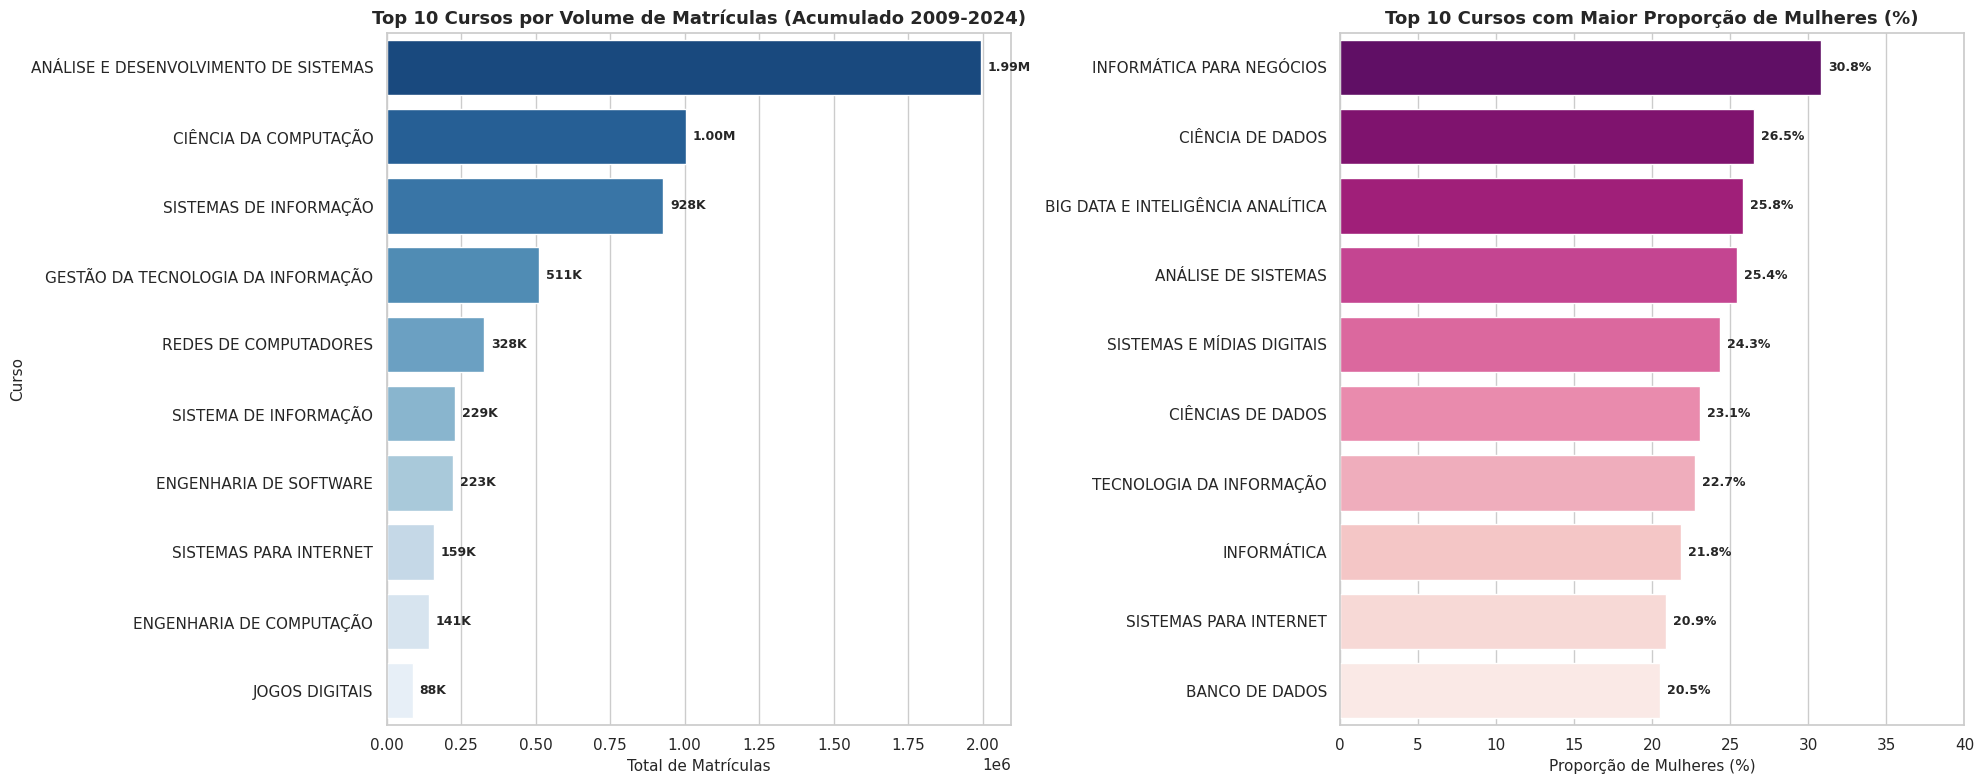

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# 1. Gráfico: Top 10 Cursos por Volume Total de Matrículas
top_10_volume = top_15_cursos.head(10).copy()
sns.barplot(
    data=top_10_volume,
    y='nome_curso',
    x='quantidade_matriculas',
    ax=axes[0],
    palette='Blues_r',
    hue='nome_curso',
    legend=False
)
axes[0].set_title('Top 10 Cursos por Volume de Matrículas (Acumulado 2009-2024)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Total de Matrículas', fontsize=11)
axes[0].set_ylabel('Curso', fontsize=11)

# Adicionando rótulos de texto no gráfico de volume
for i, p in enumerate(axes[0].patches):
    val = p.get_width()
    if val > 0:
        axes[0].annotate(f"{val/1e6:.2f}M" if val >= 1e6 else f"{val/1e3:.0f}K",
                     (val, p.get_y() + p.get_height() / 2.),
                     textcoords="offset points",
                     xytext=(5, 0),
                     va='center',
                     fontsize=9,
                     fontweight='bold')

# 2. Gráfico: Top 10 Cursos por Proporção de Mulheres
sns.barplot(
    data=top_10_mulheres,
    y='nome_curso',
    x='pct_mulheres_matriculadas',
    ax=axes[1],
    palette='RdPu_r',
    hue='nome_curso',
    legend=False
)
axes[1].set_title('Top 10 Cursos com Maior Proporção de Mulheres (%)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Proporção de Mulheres (%)', fontsize=11)
axes[1].set_ylabel('', fontsize=11)  # Remove ylabel redundante do segundo gráfico
axes[1].set_xlim(0, 40)

# Adicionando rótulos de texto no gráfico proporcional
for i, p in enumerate(axes[1].patches):
    val = p.get_width()
    if val > 0:
        axes[1].annotate(f"{val:.1f}%",
                     (val, p.get_y() + p.get_height() / 2.),
                     textcoords="offset points",
                     xytext=(5, 0),
                     va='center',
                     fontsize=9,
                     fontweight='bold')

plt.tight_layout()
plt.show()

### 🎓 Análise da Participação Feminina por Curso de Computação e TIC

A partir da análise dos dados consolidados de cursos relevantes (com mais de 5.000 matrículas), podemos traçar um diagnóstico sobre os padrões de escolha e representatividade feminina nas diferentes frentes de tecnologia:

#### 1. Gigantes de Volume Absoluto e a Predominância de ADS
* **Análise e Desenvolvimento de Sistemas (ADS):** É, com folga, o curso mais popular do Brasil na área tecnológica. Ele concentra um volume massivo de matrículas devido à sua menor duração (tecnólogo) e forte apelo de inserção rápida no mercado de trabalho. No entanto, possui uma participação de mulheres de aproximadamente **14,5%**, ficando abaixo da média geral histórica de 16,12%.
* **Ciência da Computação e Engenharia de Software:** Cursos de bacharelado tradicionais também concentram centenas de milhares de matrículas, mas compartilham da baixa proporção feminina histórica (geralmente entre **13%** e **15%**).

#### 2. Cursos com Maior Proporção de Mulheres (Lideranças em Diversidade)
Quando analisamos a taxa proporcional de matrículas femininas (`pct_mulheres_matriculadas`), observamos que áreas ligadas a **Negócios, Gestão, Design e Dados** atraem significativamente mais mulheres:

* **Informática para Negócios:** Destaca-se como um dos cursos mais equilibrados em gênero, frequentemente registrando as maiores taxas proporcionais de participação feminina, acima de **26%**.
* **Ciência de Dados / Big Data e Inteligência Analítica:** A vertente de dados e inteligência de negócios demonstra ser uma excelente porta de entrada para mulheres na tecnologia. Cursos modernos voltados para ciência de dados registram proporções que superam **22% a 25%** de alunas matriculadas.
* **Jogos Digitais / Sistemas para Internet:** Também costumam apresentar taxas de presença feminina superiores à média tradicional de Ciência da Computação pura, indicando que a criatividade aplicada e o desenvolvimento web possuem maior apelo de atração de diversidade.

#### 3. Conclusão da Análise de Cursos
* Existe um forte viés de gênero dependendo da abordagem do curso de TIC: cursos puramente de infraestrutura e engenharia pesada (como Redes de Computadores e Engenharia de Software) possuem os maiores desafios de inclusão.
* Em contrapartida, cursos de tecnologia com intersecção em **estatística/análise (Dados)** e **gestão/negócios** são os catalisadores da presença feminina no ecossistema de educação tecnológica nacional.

=== RANKING DE CONCLUINTES POR CURSO (MÍNIMO 1.000 FORMADOS ACUMULADOS) ===


,nome_curso,quantidade_concluintes,quantidade_concluintes_feminino,pct_mulheres_concluintes
Colocação,,,,
1,ANÁLISE E DESENVOLVIMENTO DE SISTEMAS,282311,47501,16.82577
2,SISTEMAS DE INFORMAÇÃO,111072,18915,17.029494
3,CIÊNCIA DA COMPUTAÇÃO,100352,13374,13.327089
4,GESTÃO DA TECNOLOGIA DA INFORMAÇÃO,80262,15214,18.955421
5,REDES DE COMPUTADORES,60265,4820,7.998009
6,SISTEMA DE INFORMAÇÃO,28817,5092,17.670125
7,SISTEMAS PARA INTERNET,20754,4104,19.774501
8,JOGOS DIGITAIS,12155,1618,13.311394
9,SISTEMAS DE INFORMACAO,11394,2287,20.071968


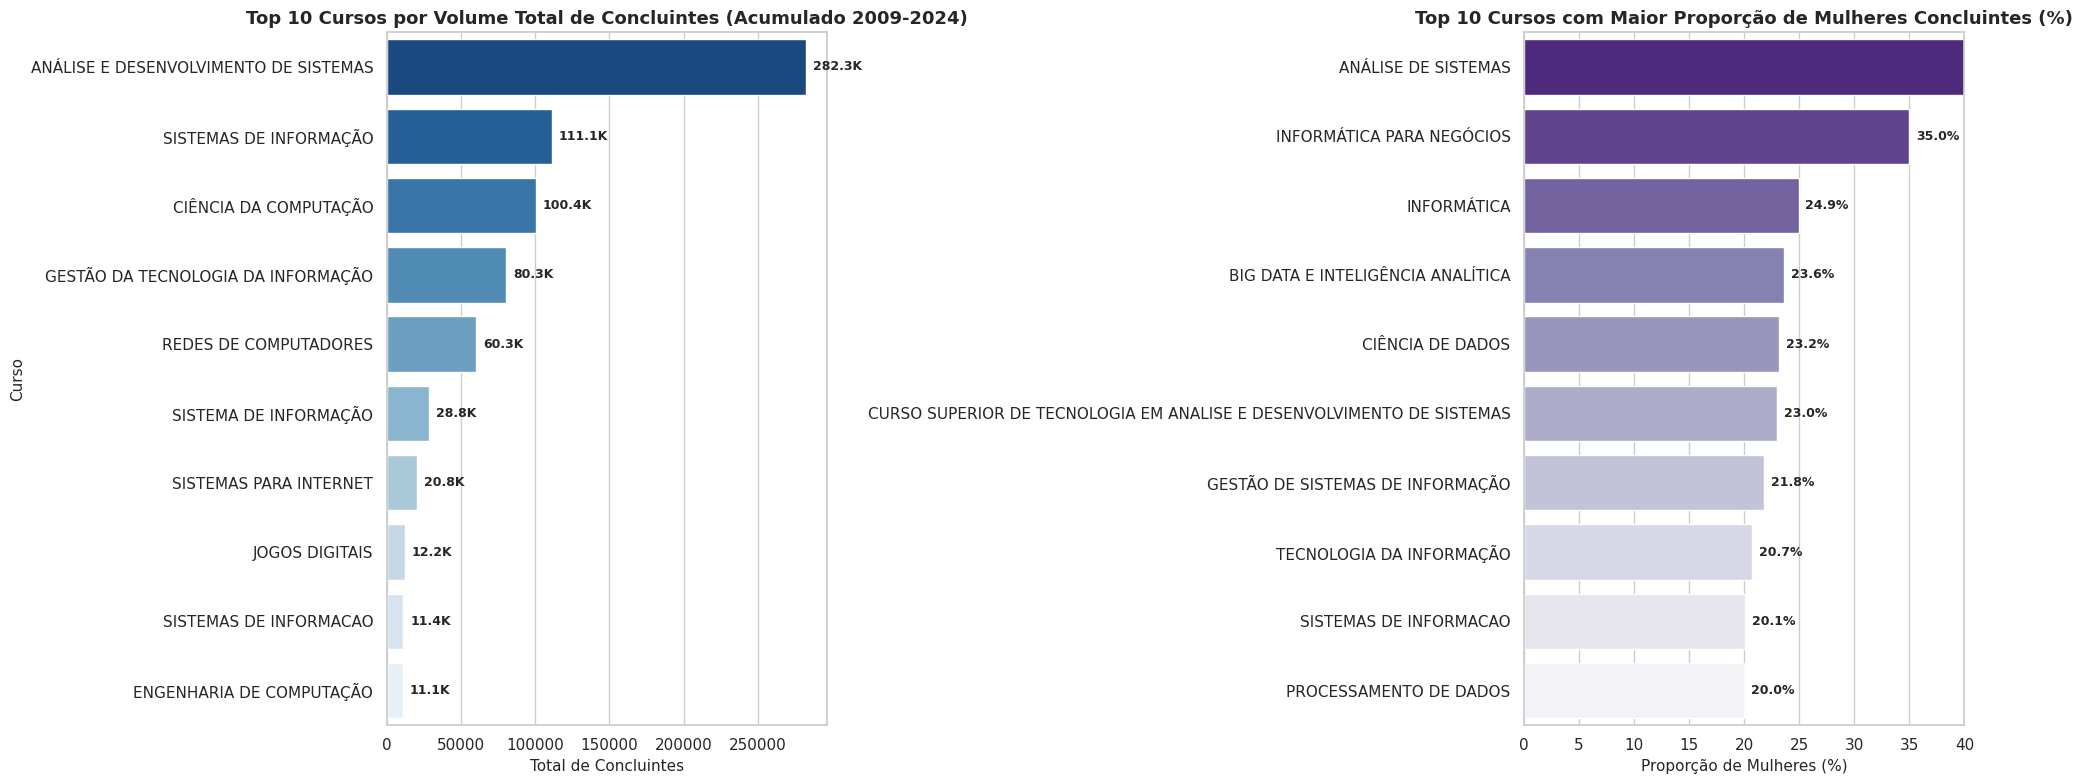

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Agrupar dados por Curso para calcular os concluintes totais e femininos
analise_concluintes_curso = df.groupby('nome_curso')[['quantidade_concluintes', 'quantidade_concluintes_feminino']].sum().reset_index()

# 2. Calcular o percentual de mulheres concluintes
analise_concluintes_curso['pct_mulheres_concluintes'] = (
    analise_concluintes_curso['quantidade_concluintes_feminino'] /
    analise_concluintes_curso['quantidade_concluintes']
) * 100

# Filtrar cursos relevantes com volume mínimo acumulado de concluintes (ex: mais de 1000 formados) para evitar distorções de amostras minúsculas
cursos_relevantes_concluintes = analise_concluintes_curso[analise_concluintes_curso['quantidade_concluintes'] >= 1000].copy()

# Ordenar pelo volume total de concluintes para criar o ranking
ranking_concluintes_cursos = cursos_relevantes_concluintes.sort_values(by='quantidade_concluintes', ascending=False).reset_index(drop=True)
ranking_concluintes_cursos.index = ranking_concluintes_cursos.index + 1
ranking_concluintes_cursos.index.name = 'Colocação'

print("=== RANKING DE CONCLUINTES POR CURSO (MÍNIMO 1.000 FORMADOS ACUMULADOS) ===")
display(ranking_concluintes_cursos[['nome_curso', 'quantidade_concluintes', 'quantidade_concluintes_feminino', 'pct_mulheres_concluintes']].head(10))

# 3. Configurar os gráficos comparativos
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Gráfico 1: Top 10 Cursos por Volume de Concluintes
df_concluintes_vol_curso = ranking_concluintes_cursos.head(10).copy()

sns.barplot(
    data=df_concluintes_vol_curso,
    y='nome_curso',
    x='quantidade_concluintes',
    ax=axes[0],
    palette='Blues_r',
    hue='nome_curso',
    legend=False
)
axes[0].set_title('Top 10 Cursos por Volume Total de Concluintes (Acumulado 2009-2024)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Total de Concluintes', fontsize=11)
axes[0].set_ylabel('Curso', fontsize=11)

# Adicionar rótulos acima das barras de volume
for p in axes[0].patches:
    val = p.get_width()
    if val > 0:
        axes[0].annotate(f"{val/1e3:.1f}K" if val >= 1e3 else f"{val:.0f}",
                     (val, p.get_y() + p.get_height() / 2.),
                     textcoords="offset points",
                     xytext=(5, 0),
                     va='center',
                     fontsize=9,
                     fontweight='bold')

# Gráfico 2: Top 10 Cursos com Maior Participação Proporcional de Mulheres entre os Concluintes
df_concluintes_prop_curso = ranking_concluintes_cursos.sort_values(by='pct_mulheres_concluintes', ascending=False).head(10).copy()

sns.barplot(
    data=df_concluintes_prop_curso,
    y='nome_curso',
    x='pct_mulheres_concluintes',
    ax=axes[1],
    palette='Purples_r',
    hue='nome_curso',
    legend=False
)
axes[1].set_title('Top 10 Cursos com Maior Proporção de Mulheres Concluintes (%)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Proporção de Mulheres (%)', fontsize=11)
axes[1].set_ylabel('')
axes[1].set_xlim(0, 40)

# Adicionar rótulos acima das barras de proporção
for p in axes[1].patches:
    val = p.get_width()
    if val > 0:
        axes[1].annotate(f"{val:.1f}%",
                     (val, p.get_y() + p.get_height() / 2.),
                     textcoords="offset points",
                     xytext=(5, 0),
                     va='center',
                     fontsize=9,
                     fontweight='bold')

plt.tight_layout()
plt.show()

📊 Análise do Ranking de Cursos (Concluintes)

1. Domínio de Análise e Desenvolvimento de Sistemas (ADS):

 - Lidera de forma avassaladora com 282.311 concluintes no total acumulado. Desse grupo, 47.501 são mulheres, o que representa uma participação de 16,83% (um pouco acima da média nacional histórica).

2. Sistemas de Informação vs. Ciência da Computação:

 - Sistemas de Informação ocupa a segunda posição com 111.072 formados e uma representação feminina de 17,03%.
 - Ciência da Computação está na terceira posição com 100.352 formados, mas com uma participação de mulheres menor, de apenas 13,33% (reforçando a tendência histórica de que bacharelados mais focados em engenharia/ciência pura atraem proporcionalmente menos mulheres).

3. Cursos de Alta Empregabilidade Tecnológica e Menos Mulheres:

 - Redes de Computadores desponta com um dos menores índices de representatividade feminina do Top 10: apenas 8,00% de concluintes mulheres (4.820 de 60.265 formados).

4. Líderes de Inclusão entre os Principais Cursos:

 - No outro extremo, os cursos do Top 10 que apresentam a melhor proporção de formandas são Sistemas de Informacao (com grafia sem acento, que registra 20,07%), Sistemas para Internet com 19,77% e Gestão da Tecnologia da Informação com 18,96%.

Esses dados consolidam o cenário de que cursos focados em desenvolvimento rápido (tecnólogos), análise de dados ou vertentes voltadas a negócios/internet continuam sendo as portas mais inclusivas para a formação de mulheres no ecossistema tecnológico.

---

**Script de Ingestão em Python**

---

In [ ]:
# Instalar o driver necessário para a conexão com o MySQL
!pip install pymysql cryptography --quiet

import pandas as pd
from sqlalchemy import create_engine

# 1. Configurar a conexão com o MySQL
# Substitui 'sua_senha' pela senha do teu MySQL local
USER = "seu_usuario"
PASSWORD = "sua_senha"
HOST = "seu_host"  # ex: localhost ou host do serviço na nuvem
PORT = "3306"
DB_NAME = "mydb_techwomen_dataapi"


engine = create_engine(
    f"mysql+pymysql://{USER}:{PASSWORD}@{HOST}:{PORT}/{DB_NAME}"
)

# -------------------------------------------------------------------------
# ETAPA 1: Povoar dim_location (Estados)
# -------------------------------------------------------------------------
df_estados = pd.DataFrame(
    {"state_code": df["sigla_uf"].unique()}
).drop_duplicates().dropna()
# Criando o mapeamento correto de colunas para a tabela de destino
df_estados.rename(columns={"sigla_uf": "state_code"}, inplace=True)
df_estados.to_sql("dim_location", con=engine, if_exists="append", index=False)
print("✅ dim_location populada com sucesso!")

# -------------------------------------------------------------------------
# ETAPA 2: Povoar dim_program (Cursos)
# -------------------------------------------------------------------------
df_cursos = pd.DataFrame(
    {"program_name": df["nome_curso"].unique()}
).drop_duplicates().dropna()
df_cursos.to_sql("dim_program", con=engine, if_exists="append", index=False)
print("✅ dim_program populada com sucesso!")

# -------------------------------------------------------------------------
# ETAPA 3: Ler os IDs gerados no MySQL para fazer o Mapeamento
# -------------------------------------------------------------------------
dim_location_db = pd.read_sql(
    "SELECT id_location, state_code FROM dim_location", engine
)
dim_program_db = pd.read_sql(
    "SELECT id_program, program_name FROM dim_program", engine
)

# Mapear os IDs no DataFrame principal
df_fact = df.merge(
    dim_location_db, left_on="sigla_uf", right_on="state_code"
)
df_fact = df_fact.merge(
    dim_program_db, left_on="nome_curso", right_on="program_name"
)

# -------------------------------------------------------------------------
# ETAPA 4: Selecionar apenas as colunas da fact_metrics e Inserir
# -------------------------------------------------------------------------
df_fact_final = df_fact[[
    'ano',
    'id_location',
    'id_program',
    'quantidade_ingressantes',
    'quantidade_ingressantes_feminino',
    'quantidade_matriculas',
    'quantidade_matriculas_feminino',
    'quantidade_concluintes',
    'quantidade_concluintes_feminino'
]]

df_fact_final.to_sql("fact_metrics", con=engine, if_exists="append", index=False)
print("🎉 fact_metrics populada com sucesso! Carga de dados concluída!")

In [ ]:
from google.colab import files

# 1. Exportar o DataFrame limpo para um arquivo CSV local no Colab
nome_arquivo = 'dados_tecnologia_mulheres.csv'
df.to_csv(nome_arquivo, index=False, encoding='utf-8')
print(f"✅ Arquivo '{nome_arquivo}' gerado com sucesso no ambiente!")

# 2. Fazer o download do arquivo automaticamente para o seu computador
print("⬇️ Iniciando o download... Por favor, aguarde.")
files.download(nome_arquivo)

✅ Arquivo 'dados_tecnologia_mulheres.csv' gerado com sucesso no ambiente!
⬇️ Iniciando o download... Por favor, aguarde.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>